# CIFAR-10 Single-Head ViT: Frozen Backbone, Joint LearnedNorm + MLPSoftmax

This notebook tests whether the two learned replacement modules alone are sufficient to recover the pretrained ViT accuracy.

Starting from the pretrained standard ViT checkpoint:

1. replace all LayerNorm modules with `LearnedLayerNormReplacement`;
2. replace all standard Softmax operators with `MLPSoftmaxReplacement`;
3. **freeze the original ViT backbone**;
4. train only the LearnedNorm and MLPSoftmax parameters together.

This experiment directly tests whether the replacement modules can adapt to the fixed pretrained backbone by themselves.

- If accuracy recovers, the two learned operators alone are sufficient.
- If accuracy does not recover, the remaining pretrained weights must co-adapt to the new normalization operators.

Attention mapping: $e^{s_i-L}$.

The default run is 50 epochs with one shared learning rate.


In [1]:
# ============================================================
# Imports and configuration
# ============================================================

import math
import random
from collections import defaultdict
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# ----------------------------
# General configuration
# ----------------------------

DATA_ROOT = "./data"
SEED = 42

BATCH_SIZE = 256
NUM_WORKERS = 4
WEIGHT_DECAY = 0.05
GRAD_CLIP_NORM = 1.0

# Model configuration
IMAGE_SIZE = 32
PATCH_SIZE = 4
DIM = 128
DEPTH = 3
MLP_RATIO = 4.0
DROPOUT = 0.1
ATTN_DROPOUT = 0.0
SOFTMAX_HIDDEN = 32

# Pretrained standard ViT checkpoint
STANDARD_CKPT = "./runs/cifar10_singlehead_vit/best.pt"

# ------------------------------------------------------------
# Frozen-backbone experiment
# ------------------------------------------------------------
JOINT_EPOCHS = 50

# One shared learning rate for LearnedNorm + MLPSoftmax.
JOINT_LR = 5e-4

JOINT_OUT_DIR = "./runs/cifar10_singlehead_vit_frozenbackbone_mlp_e"

# Curve collection configuration
CURVE_MAX_BATCHES = 20
MAX_TOKENS_PER_MODULE = 300


In [2]:
# ============================================================
# Reproducibility
# ============================================================

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


## 1. Curve collector

The collector intentionally ignores internal Softmax / LayerNorm parameters.

It only stores the **actual input-output relationship seen by each token**.


In [3]:
# ============================================================
# Token-wise end-to-end curve collector
# ============================================================

class CurveCollector:
    """
    Collect only end-to-end operator curves.

    LayerNorm:
        one token:
            x[D] -> LayerNorm(x)[D]

    Softmax:
        one query token:
            score[N] -> softmax(score)[N]

    One token therefore produces one curve.
    """

    def __init__(self, max_tokens_per_module=300):
        self.max_tokens_per_module = max_tokens_per_module

        self.layernorm_curves = defaultdict(list)
        self.softmax_curves = defaultdict(list)

    @torch.no_grad()
    def add_layernorm(self, name, x, y, mean=None, std=None):
        # x, y: [B, N, D]
        x = x.detach().float().cpu()
        y = y.detach().float().cpu()

        # [B, N, D] -> [B*N, D]
        x = x.reshape(-1, x.shape[-1])
        y = y.reshape(-1, y.shape[-1])

        remaining = (
            self.max_tokens_per_module
            - len(self.layernorm_curves[name])
        )

        if remaining <= 0:
            return

        n = min(remaining, x.shape[0])
        indices = torch.randperm(x.shape[0])[:n]

        for idx in indices:
            self.layernorm_curves[name].append(
                (
                    x[idx].numpy(),
                    y[idx].numpy(),
                )
            )

    @torch.no_grad()
    def add_softmax(self, name, scores, probs):
        # scores, probs: [B, N, N]
        scores = scores.detach().float().cpu()
        probs = probs.detach().float().cpu()

        # [B, N, N] -> [B*N, N]
        scores = scores.reshape(-1, scores.shape[-1])
        probs = probs.reshape(-1, probs.shape[-1])

        remaining = (
            self.max_tokens_per_module
            - len(self.softmax_curves[name])
        )

        if remaining <= 0:
            return

        n = min(remaining, scores.shape[0])
        indices = torch.randperm(scores.shape[0])[:n]

        for idx in indices:
            self.softmax_curves[name].append(
                (
                    scores[idx].numpy(),
                    probs[idx].numpy(),
                )
            )


## 2. Standard LayerNorm and LearnedNorm replacement

The pretrained checkpoint is first loaded with the original explicit LayerNorm. Then every LayerNorm is replaced at the same time by a tiny dynamic affine predictor:

\[
[a_t,b_t] = f_\theta(x_t), \qquad y_t = a_t x_t + b_t.
\]

The predictor is initialized close to the identity mapping, with \(a_t\approx1\) and \(b_t\approx0\).


In [4]:
# ============================================================
# Standard explicit LayerNorm
# ============================================================

class ManualLayerNorm(nn.Module):
    """
    Explicit LayerNorm used by the pretrained standard model:

        y = gamma * (x - mean) / sqrt(var + eps) + beta
    """

    def __init__(self, dim, eps=1e-5, name="ln"):
        super().__init__()

        self.gamma = nn.Parameter(torch.ones(dim))
        self.beta = nn.Parameter(torch.zeros(dim))
        self.eps = eps
        self.name = name
        self.collector = None

    def set_collector(self, collector):
        self.collector = collector

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = ((x - mean) ** 2).mean(dim=-1, keepdim=True)
        std = torch.sqrt(var + self.eps)

        y = (x - mean) / std
        y = y * self.gamma + self.beta

        if self.collector is not None and not self.training:
            self.collector.add_layernorm(
                self.name,
                x,
                y,
                mean,
                std,
            )

        return y


# ============================================================
# Learned LayerNorm replacement
# ============================================================

class LearnedLayerNormReplacement(nn.Module):
    """
    Dynamic affine replacement for LayerNorm:

        [a_t, b_t] = MLP(x_t)    # [B, N, D] -> [B, N, 2]
        y_t = a_t * x_t + b_t

    One shared tiny MLP predicts two scalars for each token.
    No explicit mean, variance, square root, or division is used.
    """

    def __init__(self, dim, hidden_dim=32, name="ln"):
        super().__init__()

        self.name = name
        self.collector = None

        self.predictor_0 = nn.Linear(dim, hidden_dim, bias=True)
        self.predictor_relu = nn.ReLU()
        self.predictor_1 = nn.Linear(hidden_dim, 2, bias=True)

        # Break symmetry while keeping the initial mapping close to
        # y = x: a ~= 1 and b ~= 0.
        nn.init.kaiming_uniform_(
            self.predictor_0.weight,
            nonlinearity="relu",
        )
        nn.init.zeros_(self.predictor_0.bias)

        nn.init.normal_(
            self.predictor_1.weight,
            mean=0.0,
            std=1e-3,
        )

        with torch.no_grad():
            self.predictor_1.bias[0] = 1.0
            self.predictor_1.bias[1] = 0.0

    def set_collector(self, collector):
        self.collector = collector

    def forward(self, x):
        state = self.predictor_0(x)
        state = self.predictor_relu(state)
        state = self.predictor_1(state)

        raw_a = state[..., 0:1]
        b = state[..., 1:2]

        # Keep only the dynamic slope in a safe positive range.
        a = torch.clamp(
            raw_a,
            min=0.05,
            max=12.0,
        )

        y = a * x + b

        if self.collector is not None and not self.training:
            self.collector.add_layernorm(
                self.name,
                x,
                y,
            )

        return y


## 3. Standard Softmax and MLP replacement

At the same moment that LayerNorm is replaced, every attention block receives a row-wise MLP normalizer:

\[
s_{q,:}\rightarrow \mathrm{MLP}\rightarrow L_q,
\]

followed by

\[
A_{qi}=e^{s_{qi}-L_q}.
\]

The original Q/K/V and output projections are kept unchanged and frozen during this experiment.


In [5]:
# ============================================================
# Direct MLP replacement for Softmax normalization
# ============================================================

class MLPSoftmaxReplacement(nn.Module):
    """
    For each complete attention-score row s_1 ... s_N:

        L = MLP([s_1, ..., s_N])
        A_i = exp(s_i - L)

    All scores in a row are available simultaneously, so no MLP
    scan is used. Each query row is processed independently and all
    rows can be evaluated in parallel.
    """

    def __init__(self, num_tokens, hidden_dim=32):
        super().__init__()

        self.num_tokens = num_tokens

        self.normalizer_mlp = nn.Sequential(
            nn.Linear(num_tokens, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1),
        )

        # Keep the final predicted normalization state close to the
        # uniform-attention scale at initialization.
        first_layer = self.normalizer_mlp[0]
        final_layer = self.normalizer_mlp[-1]

        nn.init.trunc_normal_(first_layer.weight, std=0.02)
        nn.init.zeros_(first_layer.bias)

        nn.init.normal_(final_layer.weight, mean=0.0, std=1e-3)
        # If initial scores are near zero, L ~= log(N) gives
        # exp(score - L) ~= 1/N, close to a uniform attention scale.
        nn.init.constant_(final_layer.bias, math.log(num_tokens))

    def forward(self, scores):
        # scores: [B, N_query, N_key]
        B, Nq, Nk = scores.shape

        if Nk != self.num_tokens:
            raise ValueError(
                f"MLPSoftmaxReplacement expects N_key={self.num_tokens}, "
                f"but received N_key={Nk}."
            )

        # Every complete query row is fed directly to one MLP.
        rows = scores.reshape(B * Nq, Nk)

        # One learned scalar normalization state per query row.
        L = self.normalizer_mlp(rows)
        L = L.reshape(B, Nq, 1)

        # No analytical Softmax sum or division is used.
        exponent = torch.clamp(
            scores - L,
            min=-12.0,
            max=0.0,
        )

        attn = torch.exp(exponent)

        return attn


# ============================================================
# Manual single-head self-attention
# ============================================================

class SingleHeadSelfAttention(nn.Module):
    """
    Q/K/V and output projection are unchanged throughout all stages.

    learned_softmax is None:
        use standard analytical Softmax.

    learned_softmax is an MLPSoftmaxReplacement:
        use the learned row-wise MLP normalization instead.
    """

    def __init__(
        self,
        dim,
        attn_dropout=0.0,
        proj_dropout=0.0,
        name="attn",
    ):
        super().__init__()

        self.dim = dim
        self.scale = dim ** -0.5
        self.name = name
        self.collector = None

        self.q_proj = nn.Linear(dim, dim)
        self.k_proj = nn.Linear(dim, dim)
        self.v_proj = nn.Linear(dim, dim)
        self.out_proj = nn.Linear(dim, dim)

        # Stage 1 keeps this as None. Stage 2 installs the module.
        self.learned_softmax = None

        self.attn_dropout = nn.Dropout(attn_dropout)
        self.proj_dropout = nn.Dropout(proj_dropout)

    def set_collector(self, collector):
        self.collector = collector

    def forward(self, x):
        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        scores = torch.matmul(
            q,
            k.transpose(-2, -1),
        ) * self.scale

        if self.learned_softmax is None:
            # Standard Softmax used by the original model and Stage 1.
            probs = torch.softmax(scores, dim=-1)
        else:
            # MLP replacement used from Stage 2 onward.
            probs = self.learned_softmax(scores)

        if self.collector is not None and not self.training:
            self.collector.add_softmax(
                self.name,
                scores,
                probs,
            )

        probs = self.attn_dropout(probs)

        out = torch.matmul(probs, v)
        out = self.out_proj(out)
        out = self.proj_dropout(out)

        return out


## 4. MLP and Transformer block

In [6]:
# ============================================================
# MLP
# ============================================================

class MLP(nn.Module):

    def __init__(
        self,
        dim,
        hidden_dim,
        dropout=0.0,
    ):
        super().__init__()

        self.fc1 = nn.Linear(dim, hidden_dim)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden_dim, dim)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.dropout(x)

        x = self.fc2(x)
        x = self.dropout(x)

        return x


# ============================================================
# Transformer block
# ============================================================

class TransformerBlock(nn.Module):
    """
    Pre-LN encoder block:

        x = x + Attention(LN1(x))
        x = x + MLP(LN2(x))
    """

    def __init__(
        self,
        dim,
        mlp_ratio=4.0,
        dropout=0.0,
        attn_dropout=0.0,
        block_id=0,
    ):
        super().__init__()

        self.ln1 = ManualLayerNorm(
            dim,
            name=f"block{block_id}.ln1",
        )

        self.attn = SingleHeadSelfAttention(
            dim,
            attn_dropout=attn_dropout,
            proj_dropout=dropout,
            name=f"block{block_id}.softmax",
        )

        self.ln2 = ManualLayerNorm(
            dim,
            name=f"block{block_id}.ln2",
        )

        self.mlp = MLP(
            dim=dim,
            hidden_dim=int(dim * mlp_ratio),
            dropout=dropout,
        )

    def set_collector(self, collector):
        self.ln1.set_collector(collector)
        self.attn.set_collector(collector)
        self.ln2.set_collector(collector)

    def forward(self, x):
        x = x + self.attn(
            self.ln1(x)
        )

        x = x + self.mlp(
            self.ln2(x)
        )

        return x


## 5. CIFAR-10 ViT

In [7]:
# ============================================================
# CIFAR-10 single-head ViT
# ============================================================

class CIFAR10SingleHeadViT(nn.Module):

    def __init__(
        self,
        image_size=32,
        patch_size=4,
        in_channels=3,
        num_classes=10,
        dim=128,
        depth=3,
        mlp_ratio=4.0,
        dropout=0.1,
        attn_dropout=0.0,
    ):
        super().__init__()

        assert image_size % patch_size == 0

        self.image_size = image_size
        self.patch_size = patch_size
        self.dim = dim

        patches_per_side = (
            image_size // patch_size
        )

        self.num_patches = (
            patches_per_side ** 2
        )

        patch_dim = (
            in_channels
            * patch_size
            * patch_size
        )

        self.patch_proj = nn.Linear(
            patch_dim,
            dim,
        )

        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, dim)
        )

        self.pos_embed = nn.Parameter(
            torch.zeros(
                1,
                self.num_patches + 1,
                dim,
            )
        )

        self.pos_drop = nn.Dropout(dropout)

        self.blocks = nn.ModuleList([
            TransformerBlock(
                dim=dim,
                mlp_ratio=mlp_ratio,
                dropout=dropout,
                attn_dropout=attn_dropout,
                block_id=i,
            )
            for i in range(depth)
        ])

        self.final_ln = ManualLayerNorm(
            dim,
            name="final_ln",
        )

        self.head = nn.Linear(
            dim,
            num_classes,
        )

        self._init_weights()

    def _init_weights(self):
        nn.init.trunc_normal_(
            self.pos_embed,
            std=0.02,
        )

        nn.init.trunc_normal_(
            self.cls_token,
            std=0.02,
        )

        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(
                    m.weight,
                    std=0.02,
                )

                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def set_collector(self, collector):
        for block in self.blocks:
            block.set_collector(
                collector
            )

        self.final_ln.set_collector(
            collector
        )

    def clear_collector(self):
        self.set_collector(None)

    def patchify(self, x):
        p = self.patch_size

        x = x.unfold(
            2,
            p,
            p,
        ).unfold(
            3,
            p,
            p,
        )

        x = x.permute(
            0,
            2,
            3,
            1,
            4,
            5,
        ).contiguous()

        x = x.view(
            x.size(0),
            self.num_patches,
            -1,
        )

        return x

    def forward(self, x):
        x = self.patchify(x)
        x = self.patch_proj(x)

        cls = self.cls_token.expand(
            x.size(0),
            -1,
            -1,
        )

        x = torch.cat(
            [cls, x],
            dim=1,
        )

        x = x + self.pos_embed
        x = self.pos_drop(x)

        for block in self.blocks:
            x = block(x)

        x = self.final_ln(x)

        cls_out = x[:, 0]
        logits = self.head(cls_out)

        return logits


def build_model():
    return CIFAR10SingleHeadViT(
        image_size=IMAGE_SIZE,
        patch_size=PATCH_SIZE,
        num_classes=10,
        dim=DIM,
        depth=DEPTH,
        mlp_ratio=MLP_RATIO,
        dropout=DROPOUT,
        attn_dropout=ATTN_DROPOUT,
    )


## 6. CIFAR-10 data loaders

In [8]:
# ============================================================
# Dataset
# ============================================================

def make_loaders(
    data_root="./data",
    batch_size=256,
    num_workers=4,
    seed=42,
):

    train_tf = transforms.Compose([
        transforms.RandomCrop(
            32,
            padding=4,
        ),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=(
                0.4914,
                0.4822,
                0.4465,
            ),
            std=(
                0.2470,
                0.2435,
                0.2616,
            ),
        ),
    ])

    eval_tf = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(
            mean=(
                0.4914,
                0.4822,
                0.4465,
            ),
            std=(
                0.2470,
                0.2435,
                0.2616,
            ),
        ),
    ])

    full_train_aug = datasets.CIFAR10(
        root=data_root,
        train=True,
        download=True,
        transform=train_tf,
    )

    full_train_eval = datasets.CIFAR10(
        root=data_root,
        train=True,
        download=False,
        transform=eval_tf,
    )

    test_set = datasets.CIFAR10(
        root=data_root,
        train=False,
        download=True,
        transform=eval_tf,
    )

    g = torch.Generator().manual_seed(seed)

    indices = torch.randperm(
        len(full_train_aug),
        generator=g,
    ).tolist()

    train_indices = indices[:45_000]
    val_indices = indices[45_000:]

    train_set = Subset(
        full_train_aug,
        train_indices,
    )

    # Same training samples, but augmentation disabled.
    train_eval_set = Subset(
        full_train_eval,
        train_indices,
    )

    val_set = Subset(
        full_train_eval,
        val_indices,
    )

    loader_kwargs = dict(
        batch_size=batch_size,
        num_workers=num_workers,
        pin_memory=True,
    )

    train_loader = DataLoader(
        train_set,
        shuffle=True,
        drop_last=True,
        **loader_kwargs,
    )

    train_eval_loader = DataLoader(
        train_eval_set,
        shuffle=False,
        drop_last=False,
        **loader_kwargs,
    )

    val_loader = DataLoader(
        val_set,
        shuffle=False,
        drop_last=False,
        **loader_kwargs,
    )

    test_loader = DataLoader(
        test_set,
        shuffle=False,
        drop_last=False,
        **loader_kwargs,
    )

    return (
        train_loader,
        train_eval_loader,
        val_loader,
        test_loader,
    )


train_loader, train_eval_loader, val_loader, test_loader = make_loaders(
    data_root=DATA_ROOT,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    seed=SEED,
)

print(
    len(train_loader.dataset),
    len(val_loader.dataset),
    len(test_loader.dataset),
)


45000 5000 10000


## 7. Evaluation, staged training, and replacement helpers

The optimizer receives **only parameters with `requires_grad=True`**. Each stage therefore has its own independently configured learning rate and cosine schedule.


In [9]:
# ============================================================
# Evaluation
# ============================================================

@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    criterion = nn.CrossEntropyLoss()

    total = 0
    correct = 0
    loss_sum = 0.0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        logits = model(images)
        loss = criterion(logits, labels)

        total += labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        loss_sum += loss.item() * labels.size(0)

    return loss_sum / total, correct / total


def print_eval(model, val_loader, test_loader, device, title):
    val_loss, val_acc = evaluate(model, val_loader, device)
    test_loss, test_acc = evaluate(model, test_loader, device)

    print(f"\n[{title}]")
    print(f"Validation: loss={val_loss:.4f}, acc={val_acc:.4f}")
    print(f"Test:       loss={test_loss:.4f}, acc={test_acc:.4f}")

    return {
        "val_loss": val_loss,
        "val_acc": val_acc,
        "test_loss": test_loss,
        "test_acc": test_acc,
    }


def load_checkpoint(model, ckpt_path, device, strict=True):
    ckpt_path = Path(ckpt_path)

    ckpt = torch.load(
        ckpt_path,
        map_location=device,
    )

    model.load_state_dict(
        ckpt["model"],
        strict=strict,
    )

    print(
        f"Loaded checkpoint: {ckpt_path} | "
        f"epoch={ckpt.get('epoch', '?')} | "
        f"val_acc={ckpt.get('val_acc', '?')}"
    )

    return ckpt


# ============================================================
# Module replacement helpers
# ============================================================

def replace_layernorm_with_learned(model, hidden_dim=32):
    for block_id, block in enumerate(model.blocks):
        block.ln1 = LearnedLayerNormReplacement(
            model.dim,
            hidden_dim=hidden_dim,
            name=f"block{block_id}.ln1",
        )
        block.ln2 = LearnedLayerNormReplacement(
            model.dim,
            hidden_dim=hidden_dim,
            name=f"block{block_id}.ln2",
        )

    model.final_ln = LearnedLayerNormReplacement(
        model.dim,
        hidden_dim=hidden_dim,
        name="final_ln",
    )

    return model


def enable_mlp_softmax(model, hidden_dim=32):
    num_tokens = model.num_patches + 1

    for block in model.blocks:
        block.attn.learned_softmax = MLPSoftmaxReplacement(
            num_tokens=num_tokens,
            hidden_dim=hidden_dim,
        )

    return model


# ============================================================
# Freeze / unfreeze helpers
# ============================================================

def freeze_all(model):
    for p in model.parameters():
        p.requires_grad = False


def unfreeze_replacement_modules(model):
    for module in model.modules():
        if isinstance(module, LearnedLayerNormReplacement):
            for p in module.parameters():
                p.requires_grad = True

        if isinstance(module, MLPSoftmaxReplacement):
            for p in module.parameters():
                p.requires_grad = True


def print_trainable_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    print(
        f"Trainable: {trainable:,} / {total:,} "
        f"({100.0 * trainable / total:.4f}%)"
    )


# ============================================================
# Frozen-backbone joint training
# ============================================================

def train_replacements_only(
    model,
    train_loader,
    val_loader,
    device,
    epochs,
    lr,
    weight_decay,
    out_dir,
    grad_clip_norm=1.0,
):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    trainable_params = [
        p for p in model.parameters()
        if p.requires_grad
    ]

    if not trainable_params:
        raise RuntimeError("No trainable parameters found.")

    optimizer = torch.optim.AdamW(
        trainable_params,
        lr=lr,
        weight_decay=weight_decay,
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs,
    )

    criterion = nn.CrossEntropyLoss()
    best_val_acc = -float("inf")

    print(
        f"\nFrozen-backbone replacement training: "
        f"lr={lr:.3e}, epochs={epochs}"
    )
    print_trainable_parameters(model)

    for epoch in range(1, epochs + 1):
        model.train()

        total = 0
        correct = 0
        loss_sum = 0.0

        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels)

            if not torch.isfinite(loss):
                raise RuntimeError(
                    "Frozen-backbone training: non-finite loss detected."
                )

            loss.backward()

            if grad_clip_norm is not None:
                torch.nn.utils.clip_grad_norm_(
                    trainable_params,
                    max_norm=grad_clip_norm,
                )

            optimizer.step()

            total += labels.size(0)
            correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()
            loss_sum += loss.item() * labels.size(0)

        scheduler.step()

        train_loss = loss_sum / total
        train_acc = correct / total
        val_loss, val_acc = evaluate(
            model,
            val_loader,
            device,
        )

        current_lr = scheduler.get_last_lr()[0]

        print(
            f"Frozen Backbone | "
            f"Epoch {epoch:03d}/{epochs} | "
            f"lr={current_lr:.3e} | "
            f"train loss={train_loss:.4f} acc={train_acc:.4f} | "
            f"val loss={val_loss:.4f} acc={val_acc:.4f}"
        )

        torch.save(
            {
                "stage": "Frozen Backbone",
                "epoch": epoch,
                "model": model.state_dict(),
                "optimizer": optimizer.state_dict(),
                "val_acc": val_acc,
            },
            out_dir / "last.pt",
        )

        if val_acc > best_val_acc:
            best_val_acc = val_acc

            torch.save(
                {
                    "stage": "Frozen Backbone",
                    "epoch": epoch,
                    "model": model.state_dict(),
                    "val_acc": val_acc,
                },
                out_dir / "best.pt",
            )

    print(
        f"Frozen Backbone: best validation accuracy={best_val_acc:.4f}"
    )


## 8. Replace both operators, freeze the backbone, and train only the replacements

The pretrained standard ViT is loaded first. Then all LayerNorm and Softmax operators are replaced simultaneously.

After replacement:

- all original ViT parameters are frozen;
- all LearnedNorm parameters are trainable;
- all MLPSoftmax parameters are trainable.

Only the two replacement families are optimized.


In [10]:
# ============================================================
# Build and load the pretrained STANDARD model
# ============================================================

model = build_model().to(device)

num_params = sum(
    p.numel()
    for p in model.parameters()
)

print(model)
print(f"Standard model parameters: {num_params:,}")

load_checkpoint(
    model,
    STANDARD_CKPT,
    device,
)

standard_metrics = print_eval(
    model,
    val_loader,
    test_loader,
    device,
    title="Pretrained standard model",
)


CIFAR10SingleHeadViT(
  (patch_proj): Linear(in_features=48, out_features=128, bias=True)
  (pos_drop): Dropout(p=0.1, inplace=False)
  (blocks): ModuleList(
    (0-2): 3 x TransformerBlock(
      (ln1): ManualLayerNorm()
      (attn): SingleHeadSelfAttention(
        (q_proj): Linear(in_features=128, out_features=128, bias=True)
        (k_proj): Linear(in_features=128, out_features=128, bias=True)
        (v_proj): Linear(in_features=128, out_features=128, bias=True)
        (out_proj): Linear(in_features=128, out_features=128, bias=True)
        (attn_dropout): Dropout(p=0.0, inplace=False)
        (proj_dropout): Dropout(p=0.1, inplace=False)
      )
      (ln2): ManualLayerNorm()
      (mlp): MLP(
        (fc1): Linear(in_features=128, out_features=512, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=512, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (final_ln): ManualLayerNorm()
  (head): Lin

In [11]:
# ============================================================
# Replace LayerNorm + Softmax simultaneously
# Freeze original backbone
# Train only LearnedNorm + MLPSoftmax
# ============================================================

JOINT_BEST = Path(JOINT_OUT_DIR) / "best.pt"

replace_layernorm_with_learned(
    model,
    hidden_dim=32,
)

enable_mlp_softmax(
    model,
    hidden_dim=SOFTMAX_HIDDEN,
)

model = model.to(device)

# Freeze everything first, then unfreeze ONLY the new replacement modules.
freeze_all(model)
unfreeze_replacement_modules(model)

print("\n=== Frozen-backbone joint replacement training ===")
print_trainable_parameters(model)

train_replacements_only(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    device=device,
    epochs=JOINT_EPOCHS,
    lr=JOINT_LR,
    weight_decay=WEIGHT_DECAY,
    out_dir=JOINT_OUT_DIR,
    grad_clip_norm=GRAD_CLIP_NORM,
)

load_checkpoint(
    model,
    JOINT_BEST,
    device,
)

final_metrics = print_eval(
    model,
    val_loader,
    test_loader,
    device,
    title="After frozen-backbone LearnedNorm + MLPSoftmax training",
)



=== Frozen-backbone joint replacement training ===
Trainable: 35,793 / 645,083 (5.5486%)

Frozen-backbone replacement training: lr=5.000e-04, epochs=50
Trainable: 35,793 / 645,083 (5.5486%)
Frozen Backbone | Epoch 001/50 | lr=4.995e-04 | train loss=1224.8389 acc=0.1661 | val loss=2.1118 acc=0.2096
Frozen Backbone | Epoch 002/50 | lr=4.980e-04 | train loss=2.1003 acc=0.2086 | val loss=2.0438 acc=0.2312
Frozen Backbone | Epoch 003/50 | lr=4.956e-04 | train loss=2.0471 acc=0.2300 | val loss=2.0071 acc=0.2654
Frozen Backbone | Epoch 004/50 | lr=4.921e-04 | train loss=2.0095 acc=0.2496 | val loss=1.9482 acc=0.2834
Frozen Backbone | Epoch 005/50 | lr=4.878e-04 | train loss=1.9814 acc=0.2574 | val loss=1.9204 acc=0.2900
Frozen Backbone | Epoch 006/50 | lr=4.824e-04 | train loss=1.9621 acc=0.2647 | val loss=1.9053 acc=0.3000
Frozen Backbone | Epoch 007/50 | lr=4.762e-04 | train loss=1.9443 acc=0.2734 | val loss=1.8840 acc=0.3084
Frozen Backbone | Epoch 008/50 | lr=4.691e-04 | train loss=1.926

## 9. Collect token-wise curves from the frozen-backbone replacement model


In [12]:
# ============================================================
# Collect curves
# ============================================================

@torch.no_grad()
def collect_operator_curves(
    model,
    loader,
    device,
    max_batches=20,
    max_tokens_per_module=300,
):

    collector = CurveCollector(
        max_tokens_per_module=max_tokens_per_module
    )

    model.eval()
    model.set_collector(
        collector
    )

    for batch_idx, (
        images,
        labels,
    ) in enumerate(loader):

        if (
            max_batches is not None
            and batch_idx >= max_batches
        ):
            break

        images = images.to(
            device,
            non_blocking=True,
        )

        _ = model(images)

    model.clear_collector()

    return collector


train_curve_collector = collect_operator_curves(
    model=model,
    loader=train_eval_loader,
    device=device,
    max_batches=CURVE_MAX_BATCHES,
    max_tokens_per_module=MAX_TOKENS_PER_MODULE,
)

val_curve_collector = collect_operator_curves(
    model=model,
    loader=val_loader,
    device=device,
    max_batches=CURVE_MAX_BATCHES,
    max_tokens_per_module=MAX_TOKENS_PER_MODULE,
)

print(
    "Collected train and validation curves."
)


Collected train and validation curves.


## 10. Plot functions

Each semi-transparent line corresponds to **one token**.

### MLPSoftmax

For one query token, the attention scores are sorted by input value and the corresponding learned attention values are reordered using the same indices.

### LearnedNorm

For one token, the input activation values are sorted and the corresponding dynamic-affine outputs are reordered using the same indices.


In [13]:
# ============================================================
# Plot token-wise Softmax curves
# ============================================================

def plot_softmax_curves(
    train_collector,
    val_collector,
    module_name,
    save_path=None,
    alpha=0.04,
):

    plt.figure(
        figsize=(8, 6)
    )

    colors = (
        plt.rcParams[
            "axes.prop_cycle"
        ].by_key()["color"]
    )

    train_curves = (
        train_collector
        .softmax_curves[module_name]
    )

    val_curves = (
        val_collector
        .softmax_curves[module_name]
    )

    for i, (
        scores,
        probs,
    ) in enumerate(train_curves):

        order = np.argsort(
            scores
        )

        plt.plot(
            scores[order],
            probs[order],
            color=colors[0],
            alpha=alpha,
            linewidth=0.8,
            label=(
                "Train tokens"
                if i == 0
                else None
            ),
        )

    for i, (
        scores,
        probs,
    ) in enumerate(val_curves):

        order = np.argsort(
            scores
        )

        plt.plot(
            scores[order],
            probs[order],
            color=colors[1],
            alpha=alpha,
            linewidth=0.8,
            label=(
                "Validation tokens"
                if i == 0
                else None
            ),
        )

    plt.xlabel(
        "Softmax input (attention score)"
    )

    plt.ylabel(
        "Softmax output probability"
    )

    plt.title(
        f"Token-wise Softmax curves: "
        f"{module_name}"
    )

    plt.grid(alpha=0.2)
    plt.legend()
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=200,
            bbox_inches="tight",
        )

    plt.show()


# ============================================================
# Plot token-wise LayerNorm curves
# ============================================================

def plot_layernorm_curves(
    train_collector,
    val_collector,
    module_name,
    save_path=None,
    alpha=0.04,
):

    plt.figure(
        figsize=(8, 6)
    )

    colors = (
        plt.rcParams[
            "axes.prop_cycle"
        ].by_key()["color"]
    )

    train_curves = (
        train_collector
        .layernorm_curves[module_name]
    )

    val_curves = (
        val_collector
        .layernorm_curves[module_name]
    )

    for i, (
        x,
        y,
    ) in enumerate(train_curves):

        order = np.argsort(
            x
        )

        plt.plot(
            x[order],
            y[order],
            color=colors[0],
            alpha=alpha,
            linewidth=0.8,
            label=(
                "Train tokens"
                if i == 0
                else None
            ),
        )

    for i, (
        x,
        y,
    ) in enumerate(val_curves):

        order = np.argsort(
            x
        )

        plt.plot(
            x[order],
            y[order],
            color=colors[1],
            alpha=alpha,
            linewidth=0.8,
            label=(
                "Validation tokens"
                if i == 0
                else None
            ),
        )

    plt.xlabel(
        "LayerNorm input"
    )

    plt.ylabel(
        "LayerNorm output"
    )

    plt.title(
        f"Token-wise LayerNorm curves: "
        f"{module_name}"
    )

    plt.grid(alpha=0.2)
    plt.legend()
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=200,
            bbox_inches="tight",
        )

    plt.show()


## 11. Select one attention module and one normalization module

Change only the two module names below to inspect different blocks.

Available attention modules:

- `block0.softmax`
- `block1.softmax`
- `block2.softmax`

Available normalization modules:

- `block0.ln1`
- `block0.ln2`
- `block1.ln1`
- `block1.ln2`
- `block2.ln1`
- `block2.ln2`
- `final_ln`


In [14]:
# ============================================================
# Choose modules
# ============================================================

SOFTMAX_MODULE = "block0.softmax"
LAYERNORM_MODULE = "block0.ln1"


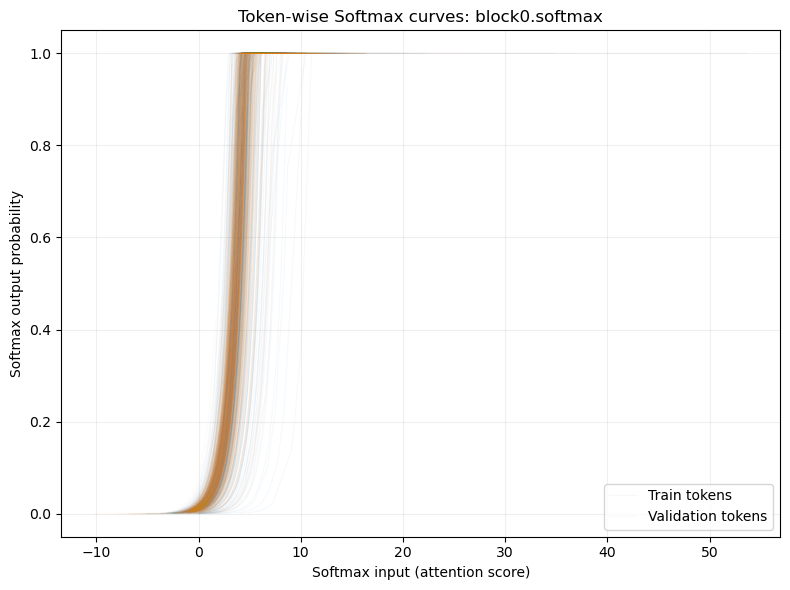

In [15]:
# ============================================================
# Softmax: all selected token curves on ONE figure
# ============================================================

plot_softmax_curves(
    train_curve_collector,
    val_curve_collector,
    module_name=SOFTMAX_MODULE,
    save_path="softmax_curves.png",
)


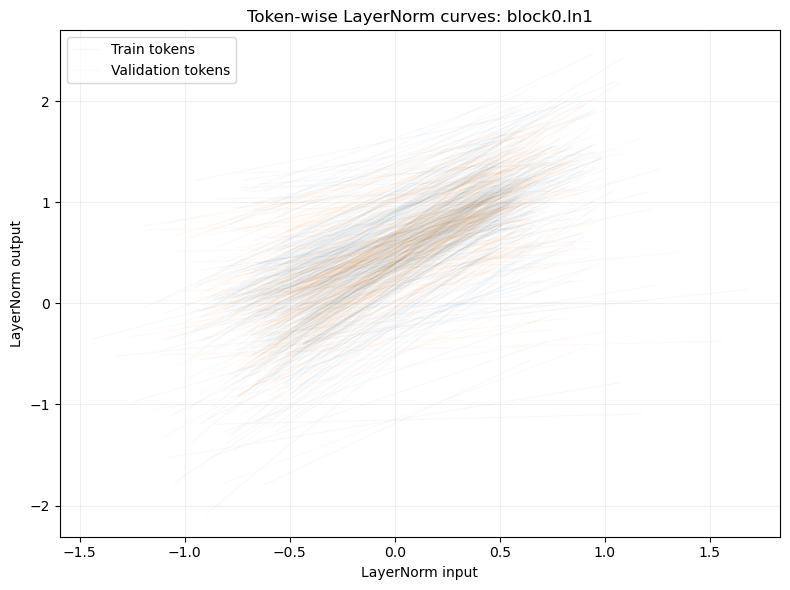

In [16]:
# ============================================================
# LayerNorm: all selected token curves on ONE figure
# ============================================================

plot_layernorm_curves(
    train_curve_collector,
    val_curve_collector,
    module_name=LAYERNORM_MODULE,
    save_path="layernorm_curves.png",
)


## Optional: inspect all three attention blocks quickly

This produces three Softmax figures and six LayerNorm figures only when explicitly executed.


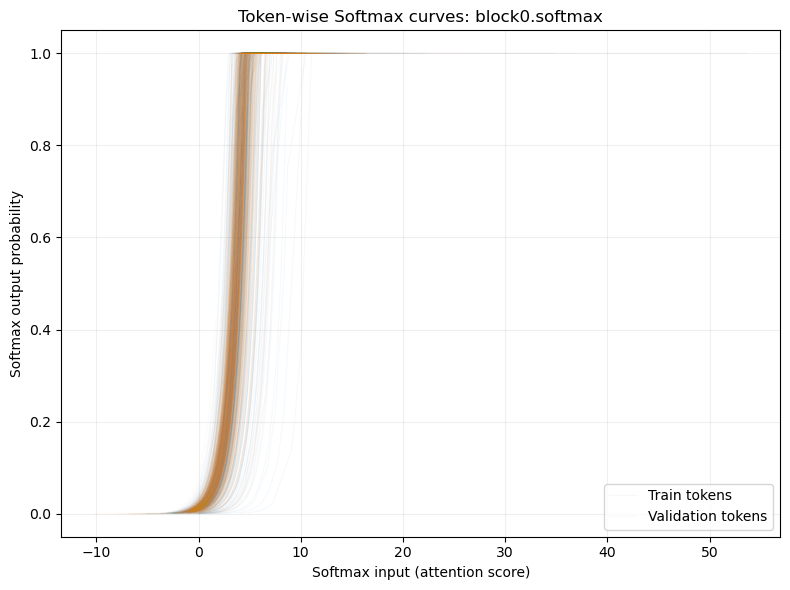

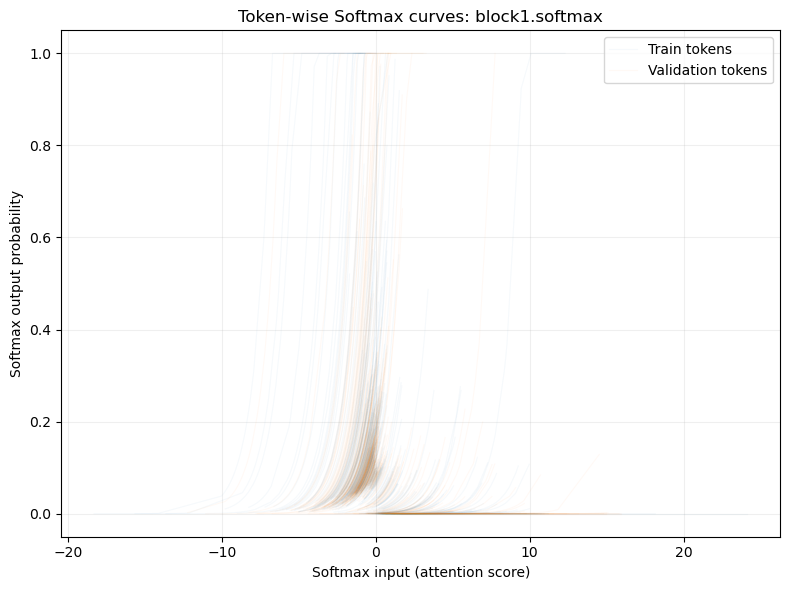

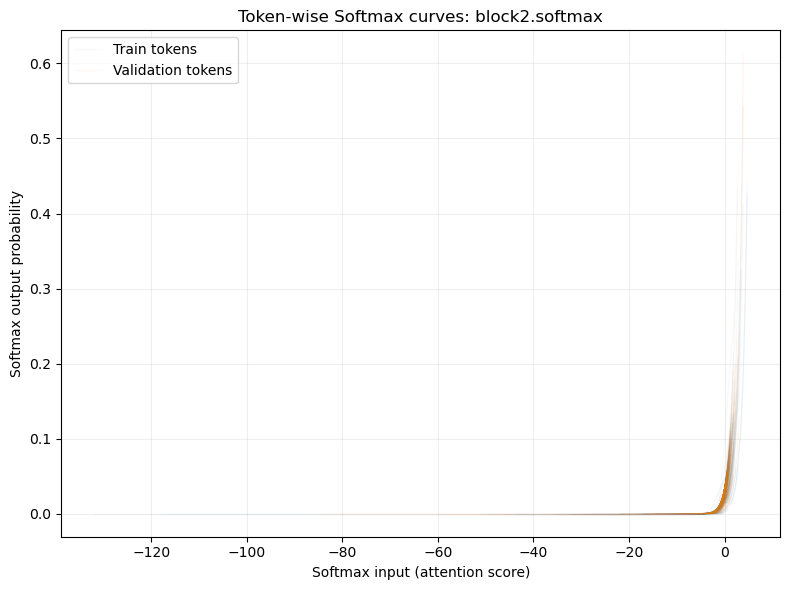

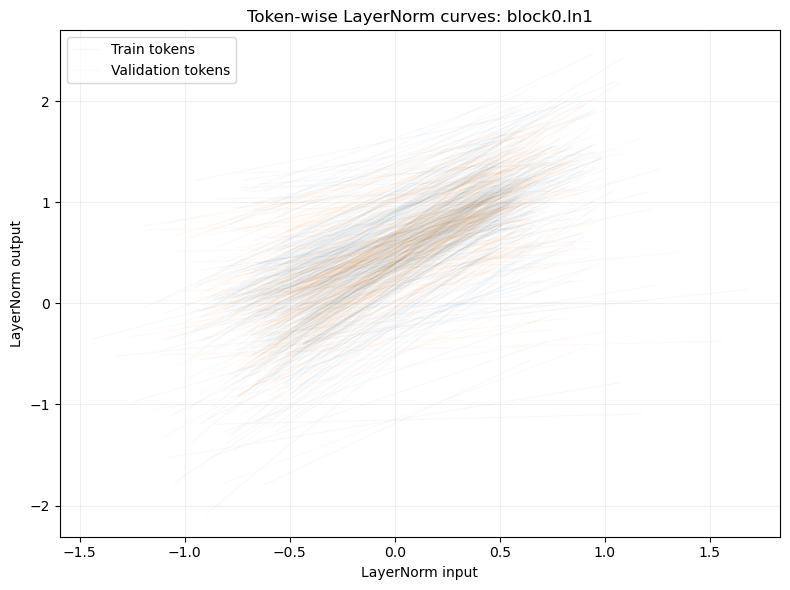

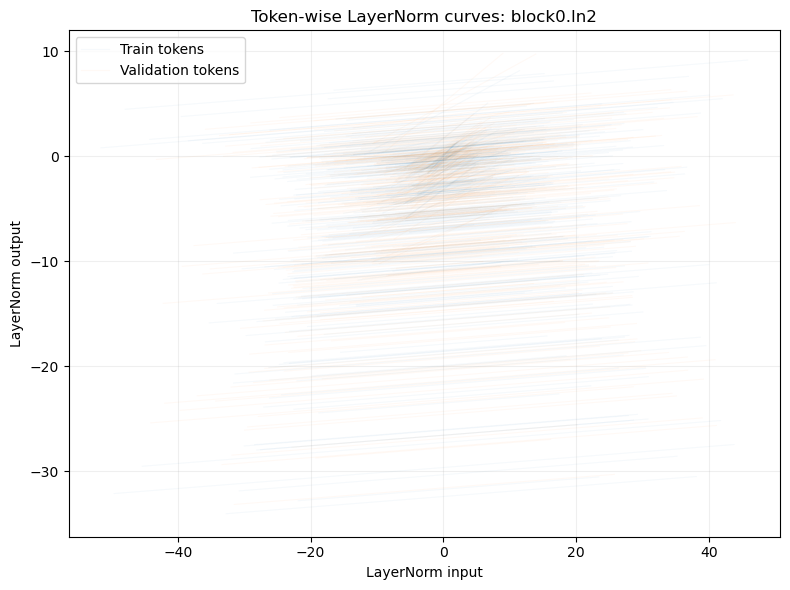

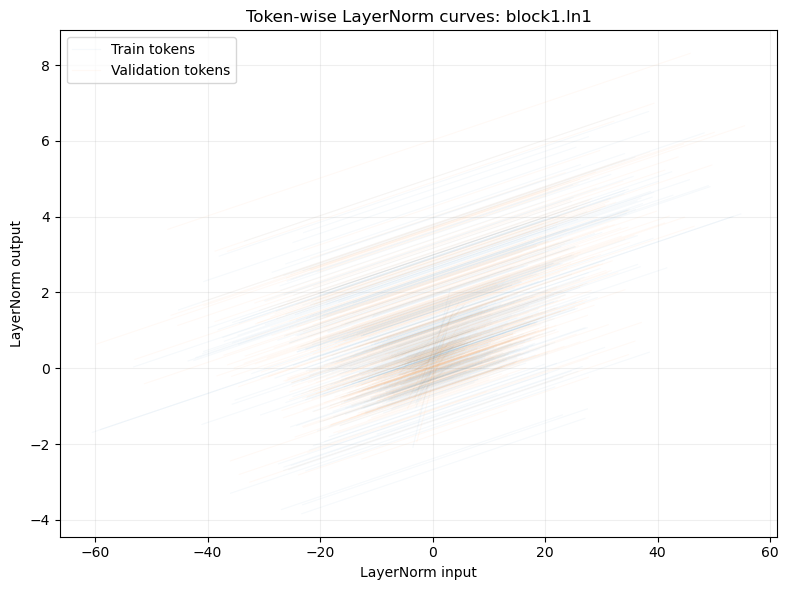

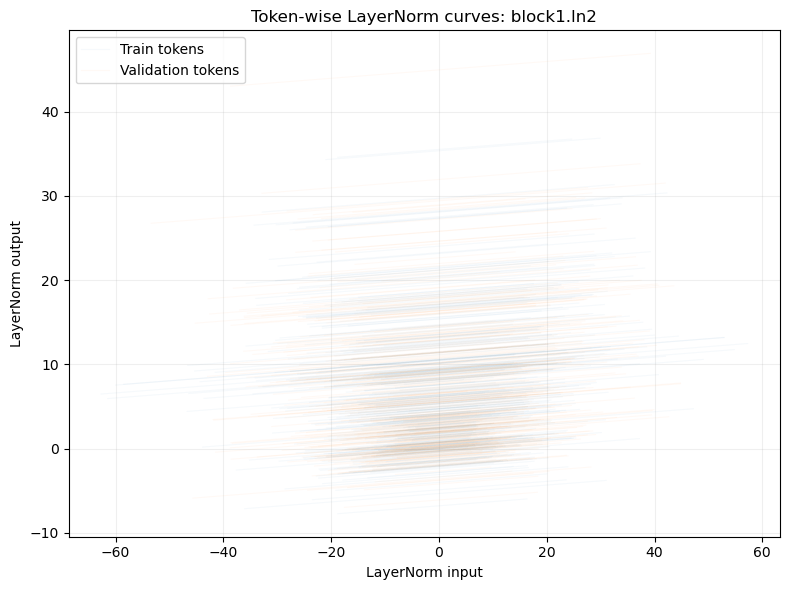

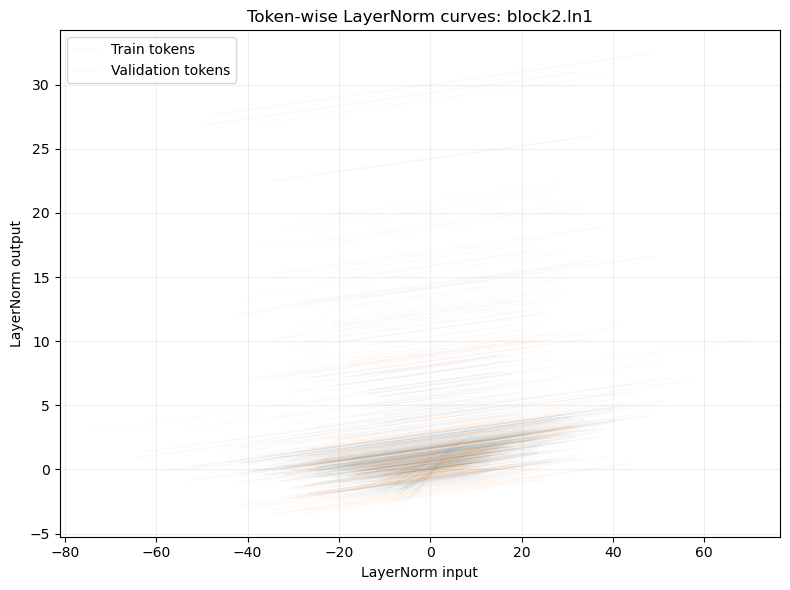

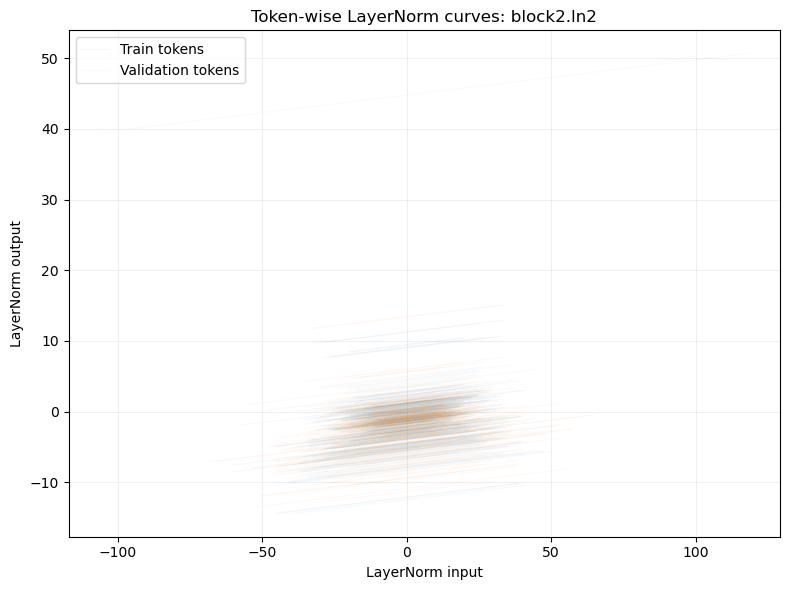

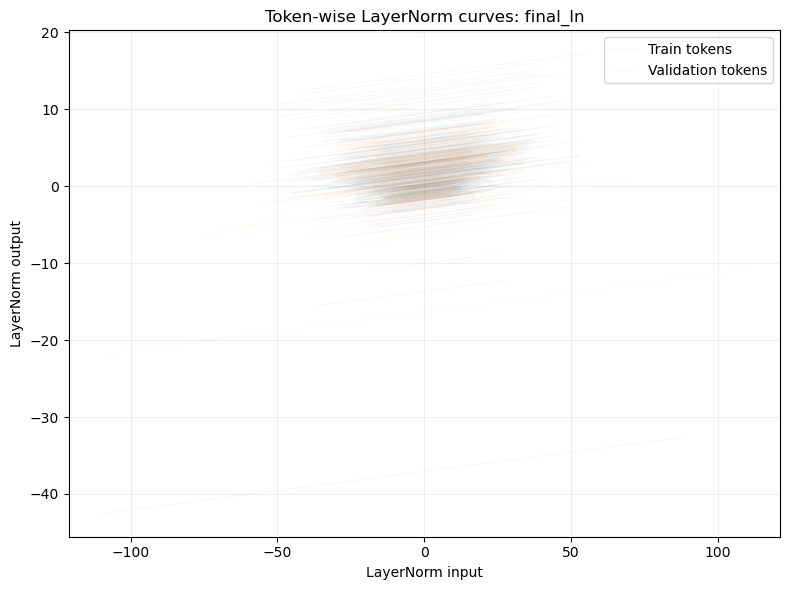

In [17]:
# Optional: uncomment if you want to inspect all blocks.

for module_name in [
    "block0.softmax",
    "block1.softmax",
    "block2.softmax",
]:
    plot_softmax_curves(
        train_curve_collector,
        val_curve_collector,
        module_name=module_name,
    )

for module_name in [
    "block0.ln1",
    "block0.ln2",
    "block1.ln1",
    "block1.ln2",
    "block2.ln1",
    "block2.ln2",
    "final_ln",
]:
    plot_layernorm_curves(
        train_curve_collector,
        val_curve_collector,
        module_name=module_name,
    )
